# Pilot and saved results

**Built with PriorLabs-TabPFN**

The Setting 2 pilot runs all models, including EXAONE, for 20 Monte Carlo repetitions.

### Python environment
From the project root, install the locked environment with `uv sync --locked --group notebook`. Select its `.venv/bin/python` as the notebook kernel. Restart the notebook kernel after changing its environment.


### Load the Core Functions and Check Packages

In [1]:
# Import medfm 
from medfm import SETTINGS, simulation, save_outputs, calculate_bayes_auc
from medfm.config import SIM_RESULTS_DIR

# Save pilot results, tables, and plots in io/sim_results/pilot_setting2/.
SAVE_PILOT_OUTPUT = True


## Check foundation model defaults

Run this cell to read ensemble defaults and checkpoint filenames from the installed packages.


In [ ]:
import inspect
from importlib import import_module

import pandas as pd
from exaonetabular.presets import released_checkpoint
from tabicl import TabICLClassifier

model_info = []
for name, package, checkpoint_method in [
    ("TabPFN 2.5", "tabpfn_v25", "get_classifier_v2_5"),
    ("TabPFN 2.6", "tabpfn_v26", "get_classifier_v2_6"),
    ("TabPFN 3", "tabpfn_v3", "get_classifier_v3"),
    ("TabPFN 3.5", "tabpfn_v35", "get_v3_5"),
]:
    classifier = import_module(package).TabPFNClassifier
    model_source = import_module(f"{package}.model_loading").ModelSource
    ensemble = inspect.signature(classifier).parameters["n_estimators"].default
    checkpoint = getattr(model_source, checkpoint_method)().default_filename
    model_info.append((name, ensemble, checkpoint))

tabicl_defaults = inspect.signature(TabICLClassifier).parameters
for name, checkpoint in [
    ("TabICL v1", "tabicl-classifier-v1-20250208.ckpt"),
    ("TabICL v2", tabicl_defaults["checkpoint_version"].default),
]:
    classifier = TabICLClassifier(checkpoint_version=checkpoint)
    model_info.append((name, classifier.n_estimators, classifier.checkpoint_version))

exaone = released_checkpoint("classification")
model_info.append(("EXAONE Tabular 1.0", exaone.manifest.runtime.ensemble_count, exaone.filename))

pd.DataFrame(
    model_info, columns=["Model", "Ensemble setting", "Checkpoint filename"]
).set_index("Model")


/home/alireza.ghorbani/Documents/github/medfm/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Ensemble setting,Checkpoint filename
Model,,
TabPFN 2.5,8,tabpfn-v2.5-classifier-v2.5_default.ckpt
TabPFN 2.6,8,tabpfn-v2.6-classifier-v2.6_default.ckpt
TabPFN 3,auto,tabpfn-v3-classifier-v3_default.ckpt
TabPFN 3.5,auto,tabpfn-v3.5-20260909.safetensors
EXAONE Tabular 1.0,8,exaone-tabular-classifier-v1_default.safetensors
TabICL v1,8,tabicl-classifier-v1-20250208.ckpt
TabICL v2,8,tabicl-classifier-v2-20260212.ckpt


## Pilot: setting 2, 20 repetitions, EXAONE included




In [ ]:
cfg = SETTINGS[2]
pilot_dir = SIM_RESULTS_DIR / "pilot_setting2"

errors, warns = simulation(
    n=cfg["n"],
    mu=cfg["mu"],
    sigma1=cfg["sigma1"],
    sigma2=cfg["sigma2"],
    dist=cfg["dist"],
    iter=20,
    g_seed=2025,
    include_exaone=True,
    progress_label='Setting 2 pilot simulation iterations',
)

pilot_bayes = {"S2": calculate_bayes_auc(cfg)}

# Save pilot results s
if SAVE_PILOT_OUTPUT:
    save_outputs(
        errors, "setting2_pilot", output_dir=pilot_dir,
        meta={**cfg, "setting_id": 2, "iter": 20, "g_seed": 2025, "include_exaone": True, "bayes_auc": pilot_bayes["S2"]},
    )


Setting 2 pilot simulation iterations:  10%|█         | 2/20 [22:39<3:24:10, 680.60s/it]

## Tables from saved results

Choose `RESULTS_DIR` below. This section runs independently of the pilot and package-check cells.
Effects are within-run differences (foundation minus tree; baseline methods are summarized separately and excluded), summarized as mean and SD.


In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from medfm.config import SIM_RESULTS_DIR, REAL_RESULTS_DIR
from medfm.utils import load_fixed, read_bayes_auc, read_labels
from medfm.table_functions import (
    build_measures_table, build_best_methods_table, build_effect_table,
    build_effect_samples, METRICS,
)
from medfm.plot_functions import (
    plot_boxplots_grid, plot_roc_curves_grid,
    plot_runtime_barplot_simple,
    plot_effect_forest, plot_violin_grid,
)

# Choose any saved pilot, main simulation, sensitivity, or real-data directory.
RESULTS_DIR = SIM_RESULTS_DIR / "pilot_setting2"
# RESULTS_DIR = SIM_RESULTS_DIR / "main"
# RESULTS_DIR = SIM_RESULTS_DIR / "sensitivity"
# RESULTS_DIR = REAL_RESULTS_DIR / "main"

SAVE_REPORT_OUTPUT = True
SHOW_BAYES_AUC = True
SHOW_BAYES_ROC = True

files = {path.stem: path for path in sorted(RESULTS_DIR.glob("*.csv"))}
if not files:
    raise FileNotFoundError(f"No saved result CSV files found in {RESULTS_DIR}")
results = load_fixed(files)
names = list(results)
labels = read_labels({name: str(path) for name, path in files.items()})
bayes = read_bayes_auc(files)
tables = RESULTS_DIR / "tables"
plots = str(RESULTS_DIR / "plots") + "/"

if SAVE_REPORT_OUTPUT:
    tables.mkdir(exist_ok=True)
    (RESULTS_DIR / "plots").mkdir(exist_ok=True)

display(build_measures_table(
    results, filename="measures.csv" if SAVE_REPORT_OUTPUT else None, tables_dir=tables,
))
display(build_best_methods_table(
    results, filename="best_methods.csv" if SAVE_REPORT_OUTPUT else None, tables_dir=tables,
))
# How many top foundation models to compare against the best tree ensemble.
# 2 = best two (default), 3 = top three, 0 = all foundation models.
N_FOUNDATION_FOR_FOREST = 0

effect = build_effect_table(
    results, filename="best_vs_best.csv" if SAVE_REPORT_OUTPUT else None, tables_dir=tables,
    n_foundation=N_FOUNDATION_FOR_FOREST,
)
display(effect)
effect_samples = build_effect_samples(results, metrics=METRICS, n_foundation=N_FOUNDATION_FOR_FOREST)

# Separate population references from the fitted model results.
if bayes:
    display(pd.DataFrame(bayes).T.drop(columns=["fpr", "tpr"], errors="ignore"))


✓ measures.csv


✓ best_methods.csv


✓ best_vs_best.csv


,auc,mc_se,n_pairs,seed,method,roc_auc
setting2_pilot,0.93179,0.000797,100000,314159,Monte Carlo likelihood ratio,0.932056


## Plots from saved results

Run the saved-results cell above, then these plot cells. The simulation cell is not required.


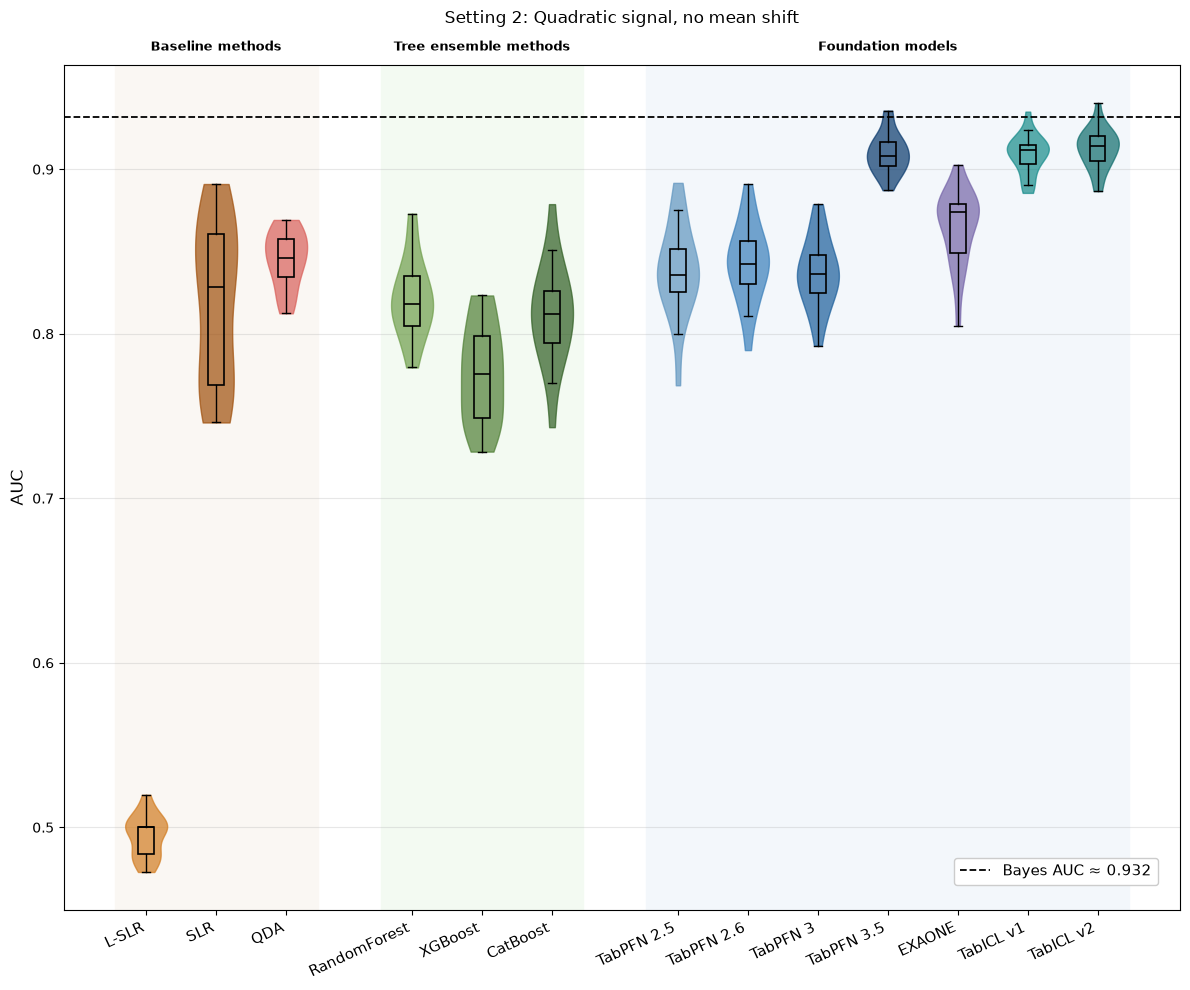

In [4]:
plot_violin_grid(results, names, labels=labels, metric="AUC", dir=plots, save_path="auc_violin.png" if SAVE_REPORT_OUTPUT else None,
                 bayes_auc=bayes, show_bayes_auc=SHOW_BAYES_AUC)


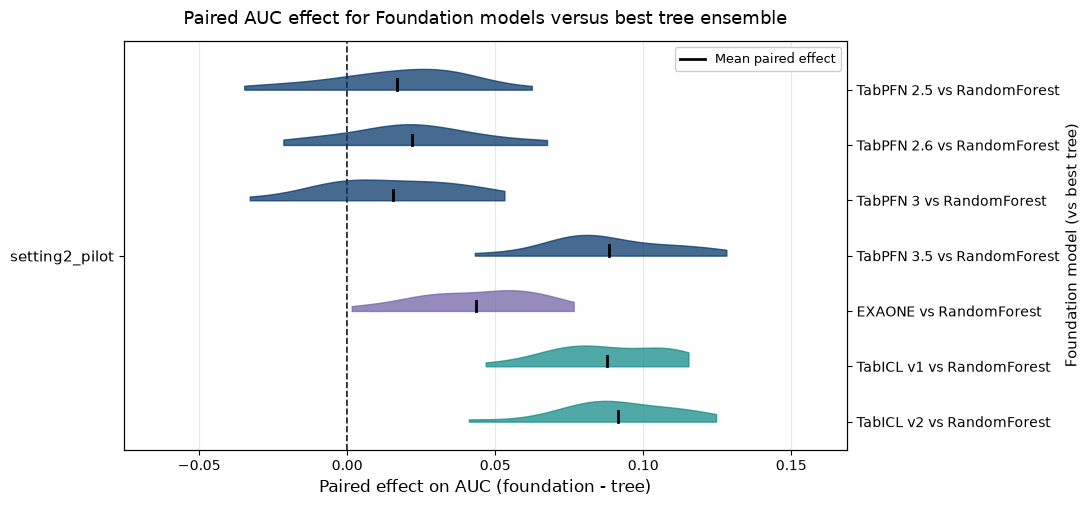

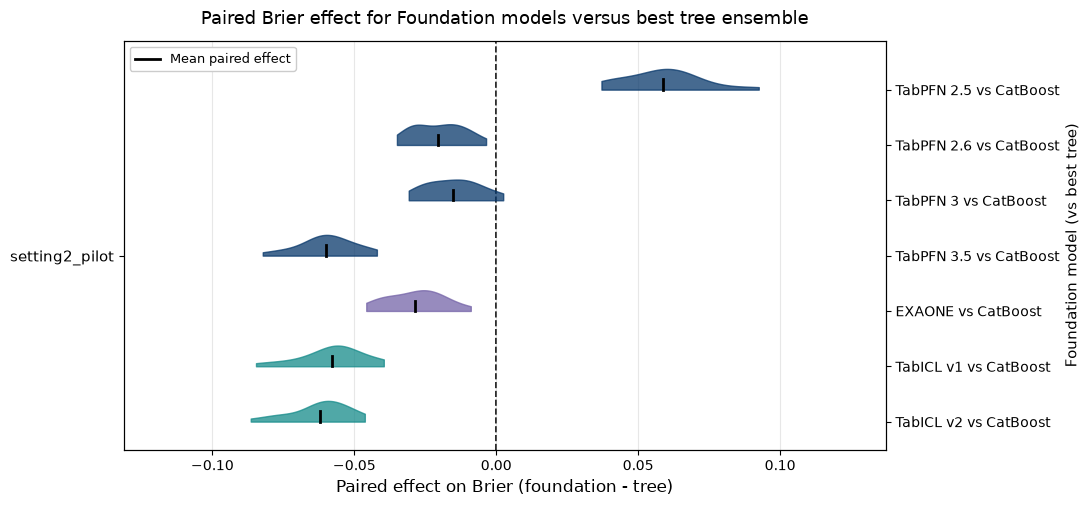

In [ ]:
# Forest plot: every selected foundation model is compared with the best
# tree ensemble model, per setting. 
# To call the top 3 instead, set N_FOUNDATION_FOR_FOREST = 3 above and re-run the tables cell; or pass
# n_foundation=3 directly when calling plot_effect_forest(results, ...).
# Use n_foundation=0 for all foundation models (the setting used here).
if effect is not None:
    plot_effect_forest(
        effect.data, effect_samples=effect_samples,
        dir=plots, save_path="forest.png" if SAVE_REPORT_OUTPUT else None,
        n_foundation=N_FOUNDATION_FOR_FOREST,
    )


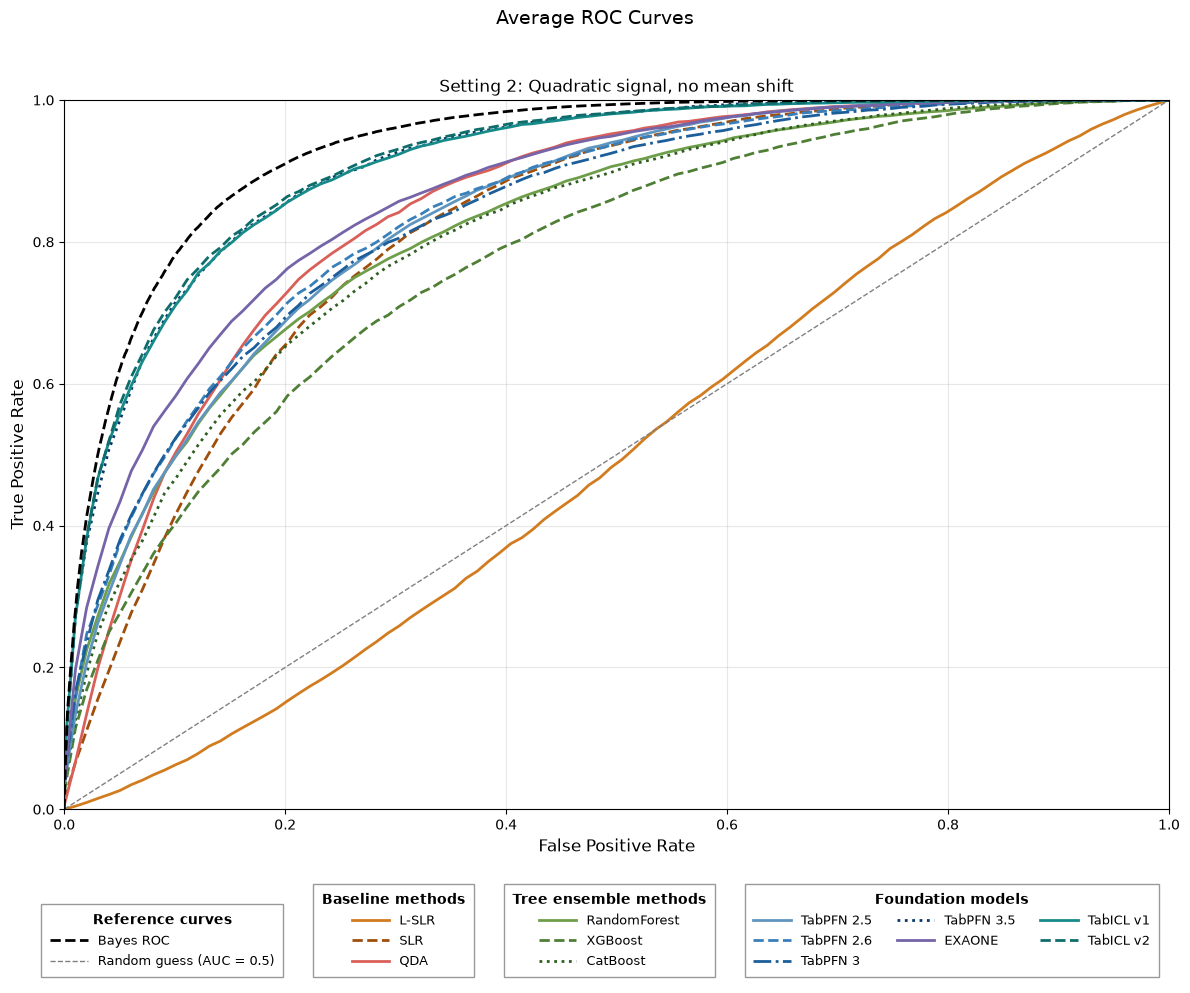

In [6]:
plot_roc_curves_grid(results, names, labels=labels, dir=plots, save_path="roc.png" if SAVE_REPORT_OUTPUT else None,
                     bayes_auc=bayes, show_bayes_roc=SHOW_BAYES_ROC)


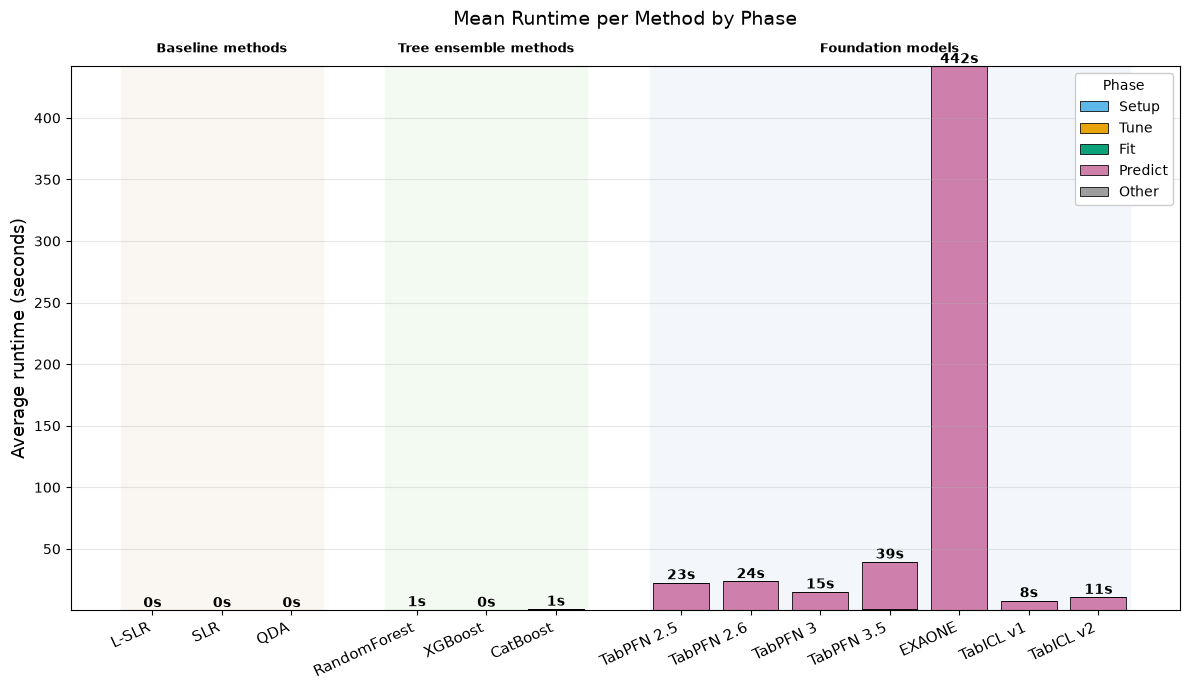

In [7]:
plot_runtime_barplot_simple(results, names, labels=labels, dir=plots, save_path="runtime.png" if SAVE_REPORT_OUTPUT else None)
